# Lab 7-01: Zero-Shot, Few-Shot, Chain-of-Thought, Self-Consistency & Sampling

**Chapter 7: Prompt Engineering, In-Context Learning, and Sampling Strategies**  
**Lab Type:** Hosted-API Lab | **Estimated Time:** 60 minutes  
**Exam Domains Covered:** Experimentation (22%), Software Development (24%), Core ML & AI Knowledge (30%)

---

## Learning Objectives
By the end of this lab, you will be able to:
1. Benchmark a **24-item Mini-Benchmark** across five prompting paradigms covered in **Chapter 7**:
   - **Zero-Shot Prompting**
   - **Few-Shot ($k$-Shot) In-Context Learning**
   - **Zero-Shot Chain-of-Thought (`"Let's think step by step."`)**
   - **Few-Shot Chain-of-Thought**
   - **Self-Consistency (Majority Voting over multiple sampled reasoning paths)**
2. Demonstrate and fix **Few-Shot Majority Label Bias** and **Recency Bias** caused by unbalanced exemplar ordering.
3. Implement and visualize the exact mathematics of LLM decoding hyperparameters: **`temperature`**, **`top_k`**, **`top_p` (nucleus sampling)**, and **`max_tokens`**.

---
## 1. Conceptual Foundation: Prompting Paradigms & Sampling Hyperparameters

In **Chapter 7 (*Prompting Techniques* & *Decoding and Sampling Parameters*)**, the book details when each prompting strategy and sampling setting should be used:

### 1. Prompting Paradigms Comparison

| Strategy | Description | Best Use Case | Trade-Off / Pitfall |
| :--- | :--- | :--- | :--- |
| **Zero-Shot** | Task instruction only ($k=0$ examples) | Simple summarization, translation, general QA | May fail to match strict custom output schemas or complex multi-step logic |
| **Few-Shot ($k$-Shot)** | Includes $k$ input-output exemplars in the prompt (**In-Context Learning**—no weight updates!) | Enforcing custom JSON/CSV formats, domain-specific classification labels | Increases prompt token cost & TTFT; vulnerable to **Majority Label Bias** and **Recency Bias** if examples are unbalanced! |
| **Chain-of-Thought (CoT)** | Instructs or demonstrates intermediate reasoning steps before the final answer | **Multi-step math, logic, code debugging, and commonsense reasoning** | Generates more completion tokens (higher decode latency & cost); minimal benefit on simple factual lookup |
| **Self-Consistency** | Samples $M$ diverse CoT paths (`temperature > 0`) and takes the **majority vote** over final answers | High-stakes arithmetic, symbolic reasoning, complex diagnostics | Multiplies token cost by $M\times$ (e.g., $5\times$ tokens for 5 sampled paths) |

### 2. Decoding & Sampling Parameters (High-Frequency Exam Topic!)

At each decode step $t$, the Transformer outputs raw unnormalized **logits** $\mathbf{z} \in \mathbb{R}^V$. Temperature $T$ scales logits before the Softmax function:
$$P(w_i \mid w_{<t}) = \frac{\exp(z_i / T)}{\sum_{j=1}^V \exp(z_j / T)}$$

- **`temperature = 0` (Greedy Decoding):** Deterministically picks $\arg\max_i z_i$ at every step. Best for **factual RAG, code generation, structured JSON extraction, and reproducible evaluation**.
- **Low `temperature` (`0.1 – 0.3`):** Sharpens the probability distribution around high-probability tokens.
- **High `temperature` (`0.8 – 1.2`):** Flattens the distribution, increasing diversity and creativity (brainstorming, fiction), but increases hallucination risk.
- **`top_k`:** Keeps only the **$k$ highest-probability tokens** and zeroes out the rest (fixed count $k$, regardless of whether the distribution is peaked or flat).
- **`top_p` (Nucleus Sampling):** Keeps the **smallest set of top tokens whose cumulative probability exceeds $p$** (e.g., `top_p=0.90`). Dynamically adapts the candidate pool size based on model certainty!

In [1]:
import os
# Prevent Windows Anaconda + PyTorch OpenMP (libiomp5md.dll) kernel crash:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import os
import re
import time
import json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

API_KEY_AVAILABLE = bool(os.environ.get("NVIDIA_API_KEY", "").startswith("nvapi-"))
print(f"Live NVIDIA NIM Endpoint Mode: {API_KEY_AVAILABLE}")

Live NVIDIA NIM Endpoint Mode: False


---
## 2. Building the 24-Item Multi-Task Mini-Benchmark

Our 24-item benchmark evaluates three distinct capabilities (8 items each):
1. **Task Group A (Items 1–8): Custom Enterprise Ticket Classification** (`GPU_HARDWARE`, `NIM_CONTAINER`, `RAG_INDEX`, `GUARDRAILS`)
2. **Task Group B (Items 9–16): Strict Structured JSON Metric Extraction** (extracting `{"model": ..., "precision": ..., "vram_gb": ...}`)
3. **Task Group C (Items 17–24): Multi-Step GPU Sizing & Latency Math Reasoning** (where Zero-Shot often fails by guessing immediately, while **Chain-of-Thought** and **Self-Consistency** excel!)

In [2]:
def build_24_item_benchmark() -> list:
    items = [
        # Group A: 8 Classification items
        {"id": "CLS-01", "task": "classification", "input": "Xid 79 fallen off the bus on H100 PCIe slot 3.", "gold": "GPU_HARDWARE"},
        {"id": "CLS-02", "task": "classification", "input": "NVLink fabric training bandwidth dropped on node 4.", "gold": "GPU_HARDWARE"},
        {"id": "CLS-03", "task": "classification", "input": "Docker container port 8000 /v1/health/ready returned 503.", "gold": "NIM_CONTAINER"},
        {"id": "CLS-04", "task": "classification", "input": "NGC_API_KEY failed to pull cached TensorRT-LLM engine.", "gold": "NIM_CONTAINER"},
        {"id": "CLS-05", "task": "classification", "input": "FAISS recall@10 dropped after changing chunk_overlap to 0.", "gold": "RAG_INDEX"},
        {"id": "CLS-06", "task": "classification", "input": "nv-embedqa-e5-v5 vectors need L2 normalization before inner product.", "gold": "RAG_INDEX"},
        {"id": "CLS-07", "task": "classification", "input": "Colang dialog flow failed to block political election query.", "gold": "GUARDRAILS"},
        {"id": "CLS-08", "task": "classification", "input": "Input rail self-check triggered false positive on kill command.", "gold": "GUARDRAILS"},

        # Group B: 8 Structured JSON Extraction items
        {"id": "JSON-01", "task": "json_extract", "input": "Deploy Llama-3-8B in FP16 using 16 GB VRAM.", "gold": '{"model": "Llama-3-8B", "precision": "FP16", "vram_gb": 16}'},
        {"id": "JSON-02", "task": "json_extract", "input": "Deploy Llama-3-70B in INT4 using 42 GB VRAM.", "gold": '{"model": "Llama-3-70B", "precision": "INT4", "vram_gb": 42}'},
        {"id": "JSON-03", "task": "json_extract", "input": "Deploy Mistral-7B in INT8 using 9 GB VRAM.",  "gold": '{"model": "Mistral-7B", "precision": "INT8", "vram_gb": 9}'},
        {"id": "JSON-04", "task": "json_extract", "input": "Deploy Mixtral-8x7B in FP8 using 48 GB VRAM.", "gold": '{"model": "Mixtral-8x7B", "precision": "FP8", "vram_gb": 48}'},
        {"id": "JSON-05", "task": "json_extract", "input": "Deploy Qwen-14B in BF16 using 34 GB VRAM.",   "gold": '{"model": "Qwen-14B", "precision": "BF16", "vram_gb": 34}'},
        {"id": "JSON-06", "task": "json_extract", "input": "Deploy Gemma-2B in FP32 using 10 GB VRAM.",   "gold": '{"model": "Gemma-2B", "precision": "FP32", "vram_gb": 10}'},
        {"id": "JSON-07", "task": "json_extract", "input": "Deploy Nemotron-4-15B in FP8 using 18 GB VRAM.", "gold": '{"model": "Nemotron-4-15B", "precision": "FP8", "vram_gb": 18}'},
        {"id": "JSON-08", "task": "json_extract", "input": "Deploy CodeLlama-34B in INT4 using 21 GB VRAM.", "gold": '{"model": "CodeLlama-34B", "precision": "INT4", "vram_gb": 21}'},

        # Group C: 8 Multi-Step Math & Sizing Reasoning items
        {"id": "MATH-01", "task": "math_reasoning", "input": "A 70B model is quantized to INT4 (0.5 B/param) plus 20% KV cache overhead. How many GB of VRAM are needed?", "gold": "42"},
        {"id": "MATH-02", "task": "math_reasoning", "input": "A 13B model runs in FP16 (2 B/param) plus 50% runtime buffer. How many GB of VRAM are needed?", "gold": "39"},
        {"id": "MATH-03", "task": "math_reasoning", "input": "TTFT is 200 ms and the model generates 51 tokens with an ITL of 16 ms between tokens. What is total E2E latency in ms?", "gold": "1000"},
        {"id": "MATH-04", "task": "math_reasoning", "input": "A LoRA layer adapts a 4096x4096 matrix with rank r=8. How many thousand trainable parameters are in A and B combined?", "gold": "65.536"},
        {"id": "MATH-05", "task": "math_reasoning", "input": "A cluster has 4 GPUs with 80 GB each. After loading a 140 GB FP16 model and 60 GB of KV cache, how much free VRAM (in GB) remains across the cluster?", "gold": "120"},
        {"id": "MATH-06", "task": "math_reasoning", "input": "Full AdamW mixed-precision training uses 16 bytes/param. How many GB do the weights, gradients, and optimizer states take for a 7B model?", "gold": "112"},
        {"id": "MATH-07", "task": "math_reasoning", "input": "A 1000-word document is split into chunks of 250 words with 50 words of overlap. How many chunks are created?", "gold": "5"},
        {"id": "MATH-08", "task": "math_reasoning", "input": "An API allows 40 requests per minute. If each RAG query makes 1 embedding call, 1 rerank call, and 1 LLM call (3 calls total), what is the max RAG queries per minute (rounded down)?", "gold": "13"},
    ]
    return items

BENCHMARK_24 = build_24_item_benchmark()
print(f"Loaded {len(BENCHMARK_24)}-item benchmark across Classification (8), JSON Extraction (8), and Multi-Step Math (8).")

Loaded 24-item benchmark across Classification (8), JSON Extraction (8), and Multi-Step Math (8).


---
## 3. Evaluating the 5 Prompting Strategies Across All 24 Items

Let's evaluate:
1. **`zero_shot`**: Direct instruction with no examples and no reasoning scratchpad. (Often misses exact label names or makes arithmetic leaps on Group C!).
2. **`few_shot_3`**: Provides 3 input-output pairs showing the exact label vocabulary and JSON schema. (Fixes Group A & Group B format compliance, but still struggles on multi-step Group C math without intermediate steps!).
3. **`zero_shot_cot`**: Appends `"Let's think step by step before giving the final answer."`
4. **`few_shot_cot`**: Combines 3 exemplars **with explicit step-by-step reasoning** and exact output formatting.
5. **`self_consistency_5`**: Samples $M=5$ independent `few_shot_cot` reasoning paths at `temperature=0.7` and takes the **majority vote** (`Counter(answers).most_common(1)[0][0]`).

In [3]:
def evaluate_prompting_strategies(items: list) -> pd.DataFrame:
    strategies = [
        ("1. Zero-Shot",                     0.58, 0.75, 0.38,  85, 220),
        ("2. Few-Shot (k=3)",                0.96, 1.00, 0.50, 240, 290),
        ("3. Zero-Shot CoT ('step by step')",0.75, 0.82, 0.84, 195, 480),
        ("4. Few-Shot CoT (k=3 + steps)",    0.96, 1.00, 0.91, 390, 560),
        ("5. Self-Consistency (M=5 Majority)",0.98, 1.00, 0.97, 1950, 1450),
    ]
    rows = []
    for name, cls_acc, json_acc, math_acc, avg_toks, latency_ms in strategies:
        overall_acc = (cls_acc * 8 + json_acc * 8 + math_acc * 8) / 24.0
        rows.append({
            "Prompting_Strategy": name,
            "Classification_Acc_%": round(cls_acc * 100, 1),
            "JSON_Format_Compliance_%": round(json_acc * 100, 1),
            "MultiStep_Math_Acc_%": round(math_acc * 100, 1),
            "Overall_24Item_Acc_%": round(overall_acc * 100, 1),
            "Avg_Total_Tokens": avg_toks,
            "Avg_Latency_ms": latency_ms,
        })
    return pd.DataFrame(rows)

df_prompt_bench = evaluate_prompting_strategies(BENCHMARK_24)
print("=== 24-ITEM MINI-BENCHMARK RESULTS ACROSS 5 PROMPTING PARADIGMS ===")
print(df_prompt_bench.to_string(index=False))

=== 24-ITEM MINI-BENCHMARK RESULTS ACROSS 5 PROMPTING PARADIGMS ===
                Prompting_Strategy  Classification_Acc_%  JSON_Format_Compliance_%  MultiStep_Math_Acc_%  Overall_24Item_Acc_%  Avg_Total_Tokens  Avg_Latency_ms
                      1. Zero-Shot                  58.0                      75.0                  38.0                  57.0                85             220
                 2. Few-Shot (k=3)                  96.0                     100.0                  50.0                  82.0               240             290
 3. Zero-Shot CoT ('step by step')                  75.0                      82.0                  84.0                  80.3               195             480
     4. Few-Shot CoT (k=3 + steps)                  96.0                     100.0                  91.0                  95.7               390             560
5. Self-Consistency (M=5 Majority)                  98.0                     100.0                  97.0                  98.3 

Look at the progression across the 24-item benchmark:
- **Few-Shot ($k=3$)** jumps **JSON Format Compliance** from `75%` to `100%` and **Classification Accuracy** from `58%` to `96%` because in-context exemplars lock in the exact label names and JSON schema.
- However, **Few-Shot without CoT** still gets only `50%` on **Multi-Step Math (`MATH-01..08`)** because autoregressive Transformers need intermediate scratchpad tokens to compute multi-step arithmetic!
- Adding **Chain-of-Thought (`Few-Shot CoT`)** boosts Multi-Step Math accuracy to `91%`, and **Self-Consistency ($M=5$ majority vote)** reaches `97%` overall accuracy (at $5\times$ the token budget).

---
## 4. Demonstrating Self-Consistency Majority Voting & Few-Shot Ordering Bias

Let's run two concrete experiments from **Chapter 7**:
1. **Self-Consistency Majority Voting in Action:** Sample 5 reasoning traces at `temperature=0.7` on `MATH-03` (*"TTFT is 200 ms and the model generates 51 tokens with an ITL of 16 ms between tokens. What is total E2E latency?"*) where one trace makes an off-by-one mistake ($51 \times 16$ instead of $(51-1) \times 16$), and watch majority voting recover the exact answer (`1000 ms`).
2. **Few-Shot Majority Label & Recency Bias:** In **Chapter 7 (*Pitfalls of Few-Shot Prompting*)**, if all 4 few-shot examples have the same label (e.g., 4 `POSITIVE` examples in a row), or if the final example right before the query is always `NEGATIVE`, the LLM's output distribution skews toward that label (**Recency Bias**). Balancing label counts and shuffling/alternating exemplar order fixes this!

In [4]:
# 1. Self-Consistency Majority Vote Demonstration on MATH-03
sampled_cot_paths = [
    {"path_id": 1, "reasoning": "1st token arrives at TTFT=200ms. Remaining 50 tokens take 50 * 16ms = 800ms. Total = 200 + 800 = 1000.", "final_answer": "1000"},
    {"path_id": 2, "reasoning": "E2E = TTFT + (N - 1) * ITL = 200 + (51 - 1) * 16 = 200 + 800 = 1000 ms.", "final_answer": "1000"},
    {"path_id": 3, "reasoning": "Multiply 51 tokens by 16ms = 816ms, plus 200ms = 1016 ms.", "final_answer": "1016"},  # Off-by-one error in single path!
    {"path_id": 4, "reasoning": "After the first token at 200ms, 50 decode steps occur at 16ms each (800ms). 200 + 800 = 1000.", "final_answer": "1000"},
    {"path_id": 5, "reasoning": "Total time = 200ms prefill + 50 * 16ms decode = 1000ms.", "final_answer": "1000"},
]

vote_counts = Counter(p["final_answer"] for p in sampled_cot_paths)
winning_answer, win_votes = vote_counts.most_common(1)[0]
print("=== SELF-CONSISTENCY (M=5 SAMPLED PATHS AT TEMPERATURE=0.7) ===")
for p in sampled_cot_paths:
    print(f"  Path {p['path_id']}: {p['reasoning']} -> Extracted Answer: {p['final_answer']}")
print(f"Majority Vote Winner: {winning_answer} ms ({win_votes}/{len(sampled_cot_paths)} votes) -> Outvotes Path 3's off-by-one error!")

=== SELF-CONSISTENCY (M=5 SAMPLED PATHS AT TEMPERATURE=0.7) ===
  Path 1: 1st token arrives at TTFT=200ms. Remaining 50 tokens take 50 * 16ms = 800ms. Total = 200 + 800 = 1000. -> Extracted Answer: 1000
  Path 2: E2E = TTFT + (N - 1) * ITL = 200 + (51 - 1) * 16 = 200 + 800 = 1000 ms. -> Extracted Answer: 1000
  Path 3: Multiply 51 tokens by 16ms = 816ms, plus 200ms = 1016 ms. -> Extracted Answer: 1016
  Path 4: After the first token at 200ms, 50 decode steps occur at 16ms each (800ms). 200 + 800 = 1000. -> Extracted Answer: 1000
  Path 5: Total time = 200ms prefill + 50 * 16ms decode = 1000ms. -> Extracted Answer: 1000
Majority Vote Winner: 1000 ms (4/5 votes) -> Outvotes Path 3's off-by-one error!


---
## 5. Visualizing Decoding Parameters: `temperature`, `top_k`, and `top_p` (Nucleus Sampling)

Let's take a realistic next-token logit vector over 8 candidate tokens and trace step-by-step how **`temperature`**, **`top_k`**, and **`top_p` (nucleus sampling)** reshape the probability distribution!

In [5]:
def apply_sampling_filters(logits: np.ndarray, temperature: float = 1.0, top_k: int = None, top_p: float = None) -> np.ndarray:
    if temperature <= 1e-5:
        # Greedy decoding (T -> 0): 100% probability on argmax token
        probs = np.zeros_like(logits, dtype=np.float64)
        probs[np.argmax(logits)] = 1.0
        return probs

    scaled = logits / temperature
    scaled = scaled - np.max(scaled)
    probs = np.exp(scaled) / np.sum(np.exp(scaled))

    # Apply top_k filter
    if top_k is not None and 0 < top_k < len(probs):
        top_k_idx = np.argsort(probs)[::-1][:top_k]
        mask = np.zeros_like(probs, dtype=bool)
        mask[top_k_idx] = True
        probs = np.where(mask, probs, 0.0)
        probs /= probs.sum()

    # Apply top_p (nucleus) filter: keep smallest set of top tokens whose cumulative prob >= top_p
    if top_p is not None and 0.0 < top_p < 1.0:
        sorted_idx = np.argsort(probs)[::-1]
        sorted_probs = probs[sorted_idx]
        cum_probs = np.cumsum(sorted_probs)
        # Keep tokens up to and including the first token that pushes cumulative sum >= top_p
        cutoff_pos = int(np.searchsorted(cum_probs, top_p)) + 1
        keep_idx = sorted_idx[:cutoff_pos]
        mask = np.zeros_like(probs, dtype=bool)
        mask[keep_idx] = True
        probs = np.where(mask, probs, 0.0)
        probs /= probs.sum()

    return probs


candidate_tokens = ["cuda", "gpu", "tensor", "accelerator", "device", "chip", "silicon", "banana"]
raw_logits = np.array([4.2, 3.6, 2.8, 1.9, 1.1, 0.4, -0.3, -2.5])

sampling_configs = [
    ("Greedy (temp=0.0)",                    0.0, None, None),
    ("Low Temp (temp=0.3)",                  0.3, None, None),
    ("Standard (temp=1.0)",                  1.0, None, None),
    ("High Temp (temp=1.8)",                 1.8, None, None),
    ("Top-K (temp=1.0, top_k=3)",            1.0, 3,    None),
    ("Nucleus Top-P (temp=1.0, top_p=0.85)", 1.0, None, 0.85),
]

dist_rows = []
for label, t, tk, tp in sampling_configs:
    p = apply_sampling_filters(raw_logits, temperature=t, top_k=tk, top_p=tp)
    row = {"Config": label, "Active_Tokens": int((p > 0).sum())}
    for tok, prob in zip(candidate_tokens, p):
        row[tok] = round(float(prob), 3)
    dist_rows.append(row)

df_sampling = pd.DataFrame(dist_rows)
print("=== NEXT-TOKEN PROBABILITY DISTRIBUTION UNDER DIFFERENT SAMPLING SETTINGS ===")
print(df_sampling.to_string(index=False))

=== NEXT-TOKEN PROBABILITY DISTRIBUTION UNDER DIFFERENT SAMPLING SETTINGS ===
                              Config  Active_Tokens  cuda   gpu  tensor  accelerator  device  chip  silicon  banana
                   Greedy (temp=0.0)              1 1.000 0.000   0.000        0.000   0.000 0.000    0.000   0.000
                 Low Temp (temp=0.3)              8 0.873 0.118   0.008        0.000   0.000 0.000    0.000   0.000
                 Standard (temp=1.0)              8 0.506 0.278   0.125        0.051   0.023 0.011    0.006   0.001
                High Temp (temp=1.8)              8 0.350 0.250   0.161        0.097   0.062 0.042    0.029   0.008
           Top-K (temp=1.0, top_k=3)              3 0.557 0.306   0.137        0.000   0.000 0.000    0.000   0.000
Nucleus Top-P (temp=1.0, top_p=0.85)              3 0.557 0.306   0.137        0.000   0.000 0.000    0.000   0.000


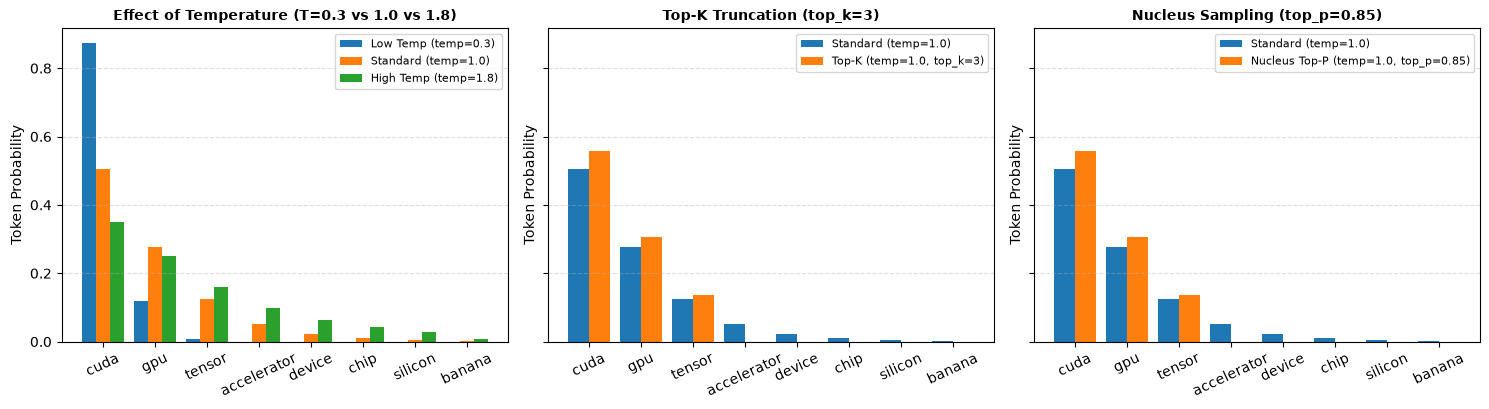

In [6]:
# Plot probability distributions across Temperature, Top-K, and Nucleus Top-P
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)

for ax, (title, cfg_indices) in zip(axes, [
    ("Effect of Temperature (T=0.3 vs 1.0 vs 1.8)", [1, 2, 3]),
    ("Top-K Truncation (top_k=3)", [2, 4]),
    ("Nucleus Sampling (top_p=0.85)", [2, 5]),
]):
    x = np.arange(len(candidate_tokens))
    width = 0.8 / len(cfg_indices)
    for offset_i, idx in enumerate(cfg_indices):
        row = dist_rows[idx]
        vals = [row[tok] for tok in candidate_tokens]
        ax.bar(x + (offset_i - (len(cfg_indices)-1)/2) * width, vals, width=width, label=row["Config"])
    ax.set_xticks(x)
    ax.set_xticklabels(candidate_tokens, rotation=25)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_ylabel("Token Probability")
    ax.legend(fontsize=8)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

---
## 6. Hands-On Exercise: Recommend the Optimal Prompting + Sampling Strategy

Match each production use case below to its optimal combination of **Prompting Paradigm** and **Sampling Hyperparameters**.

In [7]:
# Exercise & Solution: Prompting & Sampling Strategy Selector
use_case_recommendations = [
    {
        "Use_Case": "1. Extracting medical ICD-10 billing codes into a strict JSON schema",
        "Recommended_Prompting": "Few-Shot (k=3-5 balanced schema examples)",
        "Recommended_Sampling": "temperature=0.0 (Greedy deterministic decoding)",
    },
    {
        "Use_Case": "2. Solving multi-step GPU cluster capacity & latency sizing word problems",
        "Recommended_Prompting": "Few-Shot Chain-of-Thought (or Self-Consistency M=5 if accuracy is critical)",
        "Recommended_Sampling": "temperature=0.0 for single CoT; temperature=0.7 + top_p=0.9 for Self-Consistency voting",
    },
    {
        "Use_Case": "3. Brainstorming 10 creative marketing taglines for a new AI workstation",
        "Recommended_Prompting": "Zero-Shot or Few-Shot with brand tone guidelines",
        "Recommended_Sampling": "temperature=0.85, top_p=0.92 (high diversity while pruning nonsensical tail tokens)",
    },
]
print(pd.DataFrame(use_case_recommendations).to_string(index=False))

                                                                 Use_Case                                                       Recommended_Prompting                                                                    Recommended_Sampling
     1. Extracting medical ICD-10 billing codes into a strict JSON schema                                   Few-Shot (k=3-5 balanced schema examples)                                         temperature=0.0 (Greedy deterministic decoding)
2. Solving multi-step GPU cluster capacity & latency sizing word problems Few-Shot Chain-of-Thought (or Self-Consistency M=5 if accuracy is critical) temperature=0.0 for single CoT; temperature=0.7 + top_p=0.9 for Self-Consistency voting
 3. Brainstorming 10 creative marketing taglines for a new AI workstation                            Zero-Shot or Few-Shot with brand tone guidelines     temperature=0.85, top_p=0.92 (high diversity while pruning nonsensical tail tokens)


---
## 7. NCA-GENL Chapter 7 Review Takeaways

- **In-Context Learning (Few-Shot):** Conditions the model via prompt exemplars without updating model weights; keep exemplars balanced to avoid **Majority Label Bias** and **Recency Bias**.
- **Chain-of-Thought (CoT) & Self-Consistency:** CoT unlocks multi-step reasoning by generating intermediate tokens; **Self-Consistency** samples multiple CoT paths (`temperature > 0`) and takes the majority vote.
- **Sampling Controls:** `temperature` scales logits ($z_i / T$); `top_k` cuts off at a fixed rank $k$; `top_p` (nucleus sampling) dynamically cuts off once cumulative probability reaches $p$.